In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1. Dataset Overview

- **Dataset source:** Seaborn built-in `tips` practice dataset.
- **Dataset size:** 244 rows and 7 columns.
- **Features:** `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, and `size`.
- **Target:** No official target is specified in the original dataset. For earlier practice notebooks, `tip` was used as a regression target.
- **Domain:** Restaurant transactions and tipping behavior.

This dataset is used for practice and may not represent the user's original assignment dataset.

In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Rows: 244
Columns: 7

Column names:
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Data types:


,Data Type
total_bill,float64
tip,float64
sex,category
smoker,category
day,category
time,category
size,int64


## 2. Data Quality

Data quality analysis identifies missing values, duplicate records, invalid values, and incorrect data types. These issues should be documented before deciding which preprocessing techniques are appropriate.

In [3]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumerical summary:")
display(df.describe().round(2))

Missing values per column:


,Missing Values
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


Duplicate rows: 1

Data types:


,Data Type
total_bill,float64
tip,float64
sex,category
smoker,category
day,category
time,category
size,int64



Numerical summary:


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


In [4]:
print("Invalid total_bill values:", (df["total_bill"] <= 0).sum())
print("Invalid tip values:", (df["tip"] < 0).sum())
print("Invalid party sizes:", (df["size"] <= 0).sum())

Invalid total_bill values: 0
Invalid tip values: 0
Invalid party sizes: 0


## 3. Statistical Findings

Statistical findings summarize the center, spread, distribution, and potential outliers in numerical features. The mean and median describe central tendency, while standard deviation, quartiles, skewness, and the IQR method help describe variability and unusual observations.

In [5]:
numerical_df = df.select_dtypes(include="number")

stats = numerical_df.describe().T
stats["Median"] = numerical_df.median()
stats["Variance"] = numerical_df.var()
stats["Skewness"] = numerical_df.skew()

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,Median,Variance,Skewness
total_bill,244.0,19.786,8.902,3.07,13.348,17.795,24.127,50.81,17.795,79.253,1.133
tip,244.0,2.998,1.384,1.00,2.000,2.900,3.562,10.00,2.900,1.914,1.465
size,244.0,2.570,0.951,1.00,2.000,2.000,3.000,6.00,2.000,0.905,1.448


In [6]:
outlier_summary = {}

for column in numerical_df.columns:
    q1 = numerical_df[column].quantile(0.25)
    q3 = numerical_df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_summary[column] = int(
        ((numerical_df[column] < lower) |
         (numerical_df[column] > upper)).sum()
    )

display(
    pd.Series(outlier_summary, name="Potential Outliers")
    .to_frame()
)

,Potential Outliers
total_bill,9
tip,9
size,9


## 4. Relationship Findings

Relationship analysis helps identify associations between numerical and categorical features. Correlations describe the strength and direction of linear relationships between numerical variables, while grouped summaries help compare categories.

These relationships can reveal useful patterns, but correlation does not imply causation.

In [7]:
numerical_df = df.select_dtypes(include="number")

print("Correlation matrix:")
display(numerical_df.corr().round(3))

print("\nAverage tip by day:")
display(
    df.groupby("day", observed=False)["tip"]
    .mean()
    .round(2)
    .to_frame("Average Tip")
)

print("\nAverage bill by dining period:")
display(
    df.groupby("time", observed=False)["total_bill"]
    .mean()
    .round(2)
    .to_frame("Average Bill")
)

Correlation matrix:


,total_bill,tip,size
total_bill,1.000,0.676,0.598
tip,0.676,1.000,0.489
size,0.598,0.489,1.000



Average tip by day:


,Average Tip
day,
Thur,2.77
Fri,2.73
Sat,2.99
Sun,3.26



Average bill by dining period:


,Average Bill
time,
Lunch,17.17
Dinner,20.80


## 5. Visualization Findings

Visualizations help communicate important patterns that may not be obvious from raw data.

- **Histogram:** Shows the distribution and concentration of numerical values.
- **Box plot:** Highlights spread, median, and potential outliers.
- **Scatter plot:** Helps investigate relationships between numerical variables.
- **Bar chart:** Compares average values across categories.
- **Heatmap:** Summarizes correlations between numerical features.

The final report should describe the patterns actually observed in the generated plots rather than assuming a result in advance.

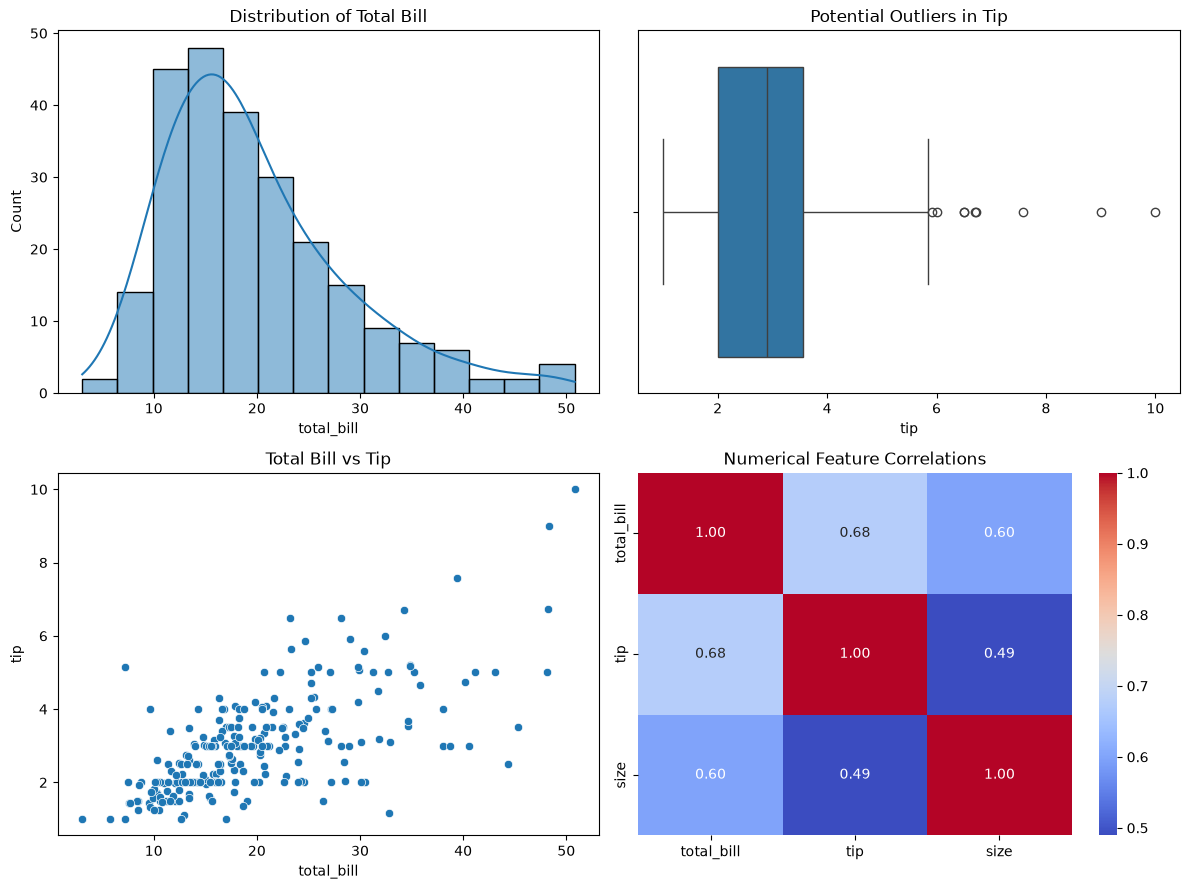

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(data=df, x="total_bill", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Total Bill")

sns.boxplot(data=df, x="tip", ax=axes[0, 1])
axes[0, 1].set_title("Potential Outliers in Tip")

sns.scatterplot(data=df, x="total_bill", y="tip", ax=axes[1, 0])
axes[1, 0].set_title("Total Bill vs Tip")

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Numerical Feature Correlations")

plt.tight_layout()
plt.show()

## 6. Potential Data Problems

The following areas should be reviewed before machine learning:

1. **Missing values:** Check each column and determine an appropriate treatment if missing data exists.
2. **Duplicates:** Investigate duplicate records before deciding whether they are genuine repeated transactions.
3. **Potential outliers:** Validate unusual values rather than automatically removing them.
4. **Data types:** Ensure numerical and categorical features use appropriate data types.
5. **Categorical consistency:** Check for inconsistent labels, whitespace, or unexpected categories.
6. **Feature suitability:** Select features relevant to the intended prediction task and avoid data leakage.

These are investigation areas; the checks and results should determine which issues actually require action.

In [9]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].value_counts(dropna=False))

print("\nDuplicate row count:", df.duplicated().sum())
print("\nMissing value count:", df.isnull().sum().sum())


Unique values in sex:
sex
Male      157
Female     87
Name: count, dtype: int64

Unique values in smoker:
smoker
No     151
Yes     93
Name: count, dtype: int64

Unique values in day:
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

Unique values in time:
time
Dinner    176
Lunch      68
Name: count, dtype: int64

Duplicate row count: 1

Missing value count: 0


## 7. Recommendations

Based on the data quality and EDA findings, the next preprocessing sprint should:

- **Missing-value treatment:** Select suitable imputation methods if missing values are present.
- **Outlier treatment:** Investigate unusual values and document whether to retain, correct, remove, or transform them.
- **Encoding:** Encode categorical variables when required by the selected model.
- **Scaling:** Scale numerical features when the chosen algorithm benefits from it.
- **Feature transformation:** Consider transformations if numerical features are strongly skewed and the transformation is appropriate.
- **Feature engineering:** Create useful features based on domain knowledge.
- **Data-type correction:** Correct inappropriate data types and standardize inconsistent categorical labels.

No complete preprocessing is performed in this notebook. The purpose is to identify and document issues before making changes.

## Conclusion

This notebook summarizes exploratory data analysis findings, including dataset structure, data quality, descriptive statistics, feature relationships, visual patterns, and potential preprocessing requirements.

The analysis helps establish an evidence-based understanding of the dataset before machine learning. Potential issues should be investigated and documented, and preprocessing decisions should be based on the actual results and the intended modeling objective.

The next sprint should address confirmed data-quality issues, prepare categorical and numerical features appropriately, and document all transformations. Full preprocessing is intentionally deferred to the next stage.